In [59]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from fooof import FOOOF

In [129]:
#CONFIGURATION
DATA_DIR = Path("DATA")
OUTPUT_DIR = Path("IAF_results")
PLOTS_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

FREQ_MIN = 2.0
FREQ_MAX = 40.0

ALPHA_MIN = 8.0
ALPHA_MAX = 14.0

REGIONS = {
    "frontal": ["AFz", "Fz", "FCz", "F1", "F2", "FC1", "FC2"],
    "posterior": ["CPz", "Pz", "POz", "P1", "P2"],
}

#HOW WIDE THE PEAK HAS TO BE TO BE DETECTED BY FOOOF
PEAK_WIDTH_LIMITS = (1.0, 2.5)

In [131]:
#FUNCTIONS

#Extract subject ID from the filename
def get_subject_id(file_path):
    name = file_path.name

    for suffix in ("-epo.fif", "_epo.fif"):
        if name.endswith(suffix):
            name = name[:-len(suffix)]
            break

    if name.endswith("_preprocessed"):
        name = name[:-len("_preprocessed")]

    return name

#Calculate mean PSD across epochs and ROI channels
def calculate_roi_psd(epochs, region_channels):
    available_channels = [
        ch for ch in region_channels
        if ch in epochs.ch_names and ch not in epochs.info["bads"]
    ]

    if not available_channels:
        return None, None, []

    roi_epochs = epochs.copy().pick(available_channels)

    sfreq = roi_epochs.info["sfreq"]
    n_times = len(roi_epochs.times)

    n_per_seg = min(round(sfreq * 2), n_times)
    n_overlap = min(round(sfreq), n_per_seg - 1)

    spectrum = roi_epochs.compute_psd(
        method="welch",
        fmin=FREQ_MIN,
        fmax=FREQ_MAX,
        n_per_seg=n_per_seg,
        n_overlap=n_overlap,
        average="mean",
        verbose=False,
    )

    psds, freqs = spectrum.get_data(return_freqs=True)
    mean_psd = psds.mean(axis=0).mean(axis=0)

    return freqs, mean_psd, available_channels

#Estimate IAF and peak power using FOOOF or PSD fallback
def estimate_iaf(freqs, psd):
    fm = FOOOF(
        peak_width_limits=PEAK_WIDTH_LIMITS,
        max_n_peaks=8,
        min_peak_height=0.0,
        peak_threshold=0.5,
        aperiodic_mode="fixed",
        verbose=False,
    )

    fm.fit(freqs, psd, [FREQ_MIN, FREQ_MAX])

    peaks = fm.peak_params_

    if peaks.size > 0:
        alpha_peaks = peaks[
            (peaks[:, 0] >= ALPHA_MIN)
            & (peaks[:, 0] <= ALPHA_MAX)
        ]
    else:
        alpha_peaks = np.empty((0, 3))

    if len(alpha_peaks) > 0:
        strongest_peak = alpha_peaks[
            np.argmax(alpha_peaks[:, 1])
        ]

        iaf = float(strongest_peak[0])

        # FOOOF peak height above the aperiodic background.
        peak_power = float(strongest_peak[1])

        method = "FOOOF"

    else:
        alpha_mask = (
            (freqs >= ALPHA_MIN)
            & (freqs <= ALPHA_MAX)
        )

        if alpha_mask.any():
            alpha_freqs = freqs[alpha_mask]
            alpha_psd = psd[alpha_mask]

            idx = np.argmax(alpha_psd)

            iaf = float(alpha_freqs[idx])
            peak_power = float(alpha_psd[idx])
            method = "PSD_max_fallback"

        else:
            iaf = np.nan
            peak_power = np.nan
            method = "No_alpha_range"

    return iaf, peak_power, method

#Plot ROI PSD and mark the estimated IAF
def plot_roi_psd(freqs, psd, iaf, subject_id, region_name, output_path):
    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(
        freqs,
        psd,
        color="royalblue",
        linewidth=1.8,
    )

    ax.axvspan(
        ALPHA_MIN,
        ALPHA_MAX,
        color="grey",
        alpha=0.12,
    )

    if np.isfinite(iaf):
        ax.axvline(
            iaf,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=f"IAF = {iaf:.2f} Hz",
        )
        ax.legend(frameon=False)

    ax.set_xlim(FREQ_MIN, FREQ_MAX)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (V²/Hz)")
    ax.set_title(f"{subject_id} - {region_name}")

    fig.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    plt.close(fig)


Subject: WB0308_F_28 | Region: frontal
- IAF: 9.98 Hz
- Alpha peak power: 7.461954e-01 V²/Hz
- Method: FOOOF


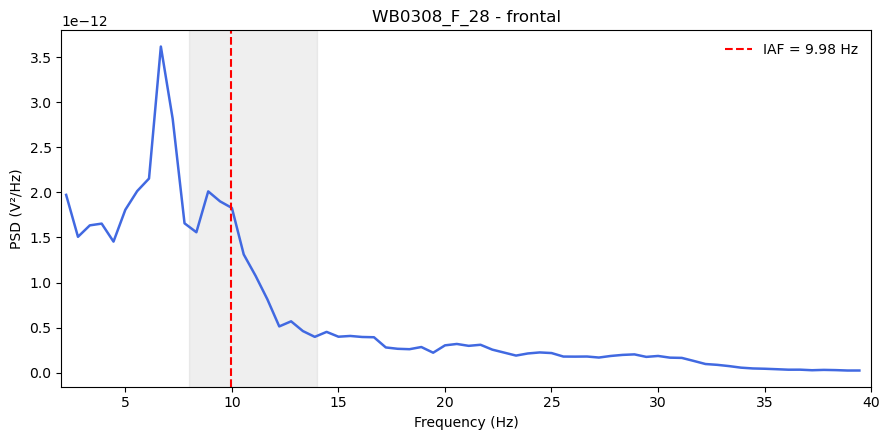


Subject: WJ2711_F_31 | Region: frontal
- IAF: 9.87 Hz
- Alpha peak power: 2.358032e-01 V²/Hz
- Method: FOOOF


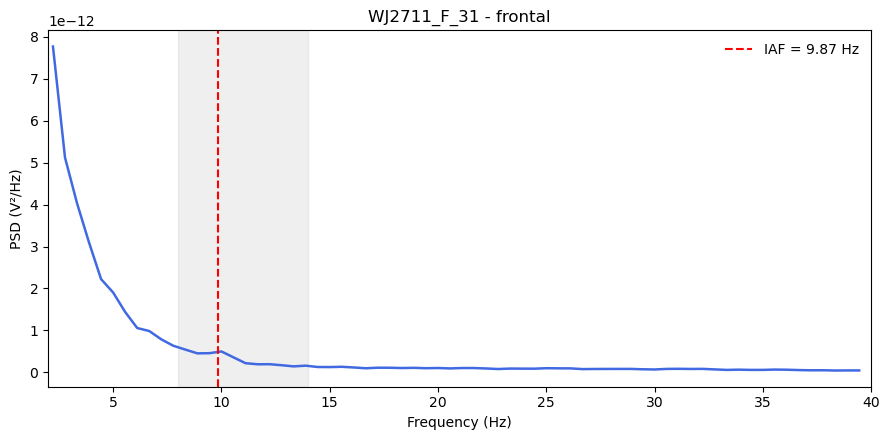


Subject: WK1312_F_29 | Region: frontal
- IAF: 11.45 Hz
- Alpha peak power: 1.206117e-01 V²/Hz
- Method: FOOOF


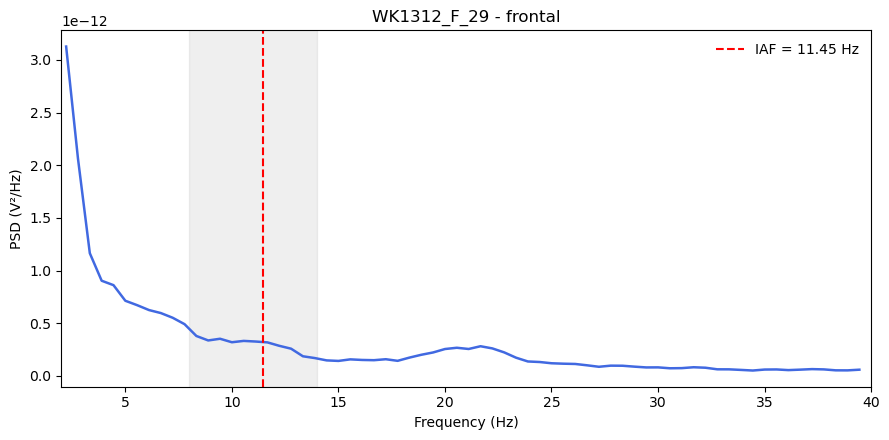


Subject: WK2201_F_21 | Region: frontal
- IAF: 10.56 Hz
- Alpha peak power: 5.432350e-13 V²/Hz
- Method: PSD_max_fallback


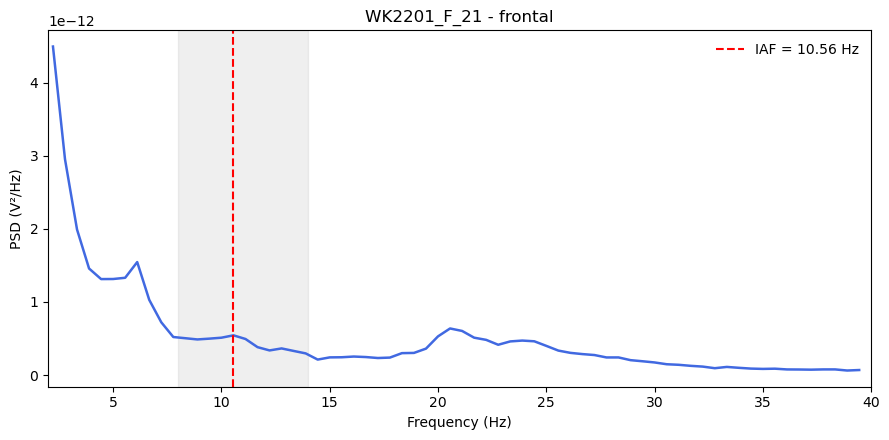


Subject: WU2110_F_21 | Region: frontal
- IAF: 8.33 Hz
- Alpha peak power: 3.181998e-13 V²/Hz
- Method: PSD_max_fallback


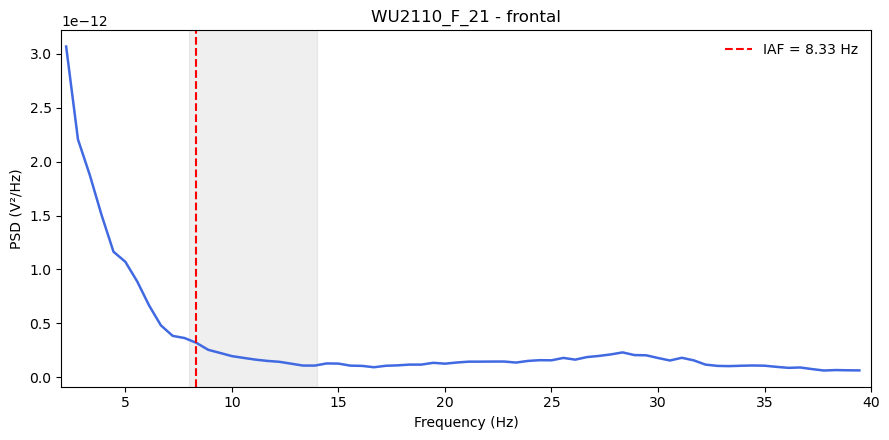


Subject: WB0308_F_28 | Region: posterior
- IAF: 10.09 Hz
- Alpha peak power: 1.078152e+00 V²/Hz
- Method: FOOOF


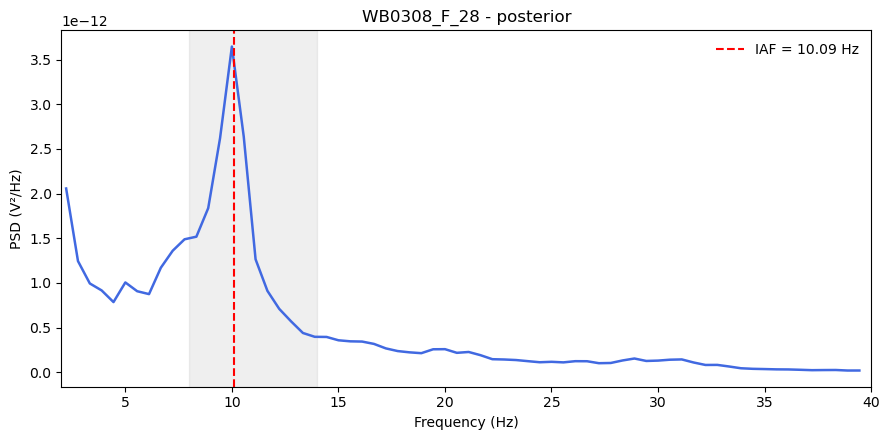


Subject: WJ2711_F_31 | Region: posterior
- IAF: 9.13 Hz
- Alpha peak power: 1.226190e-01 V²/Hz
- Method: FOOOF


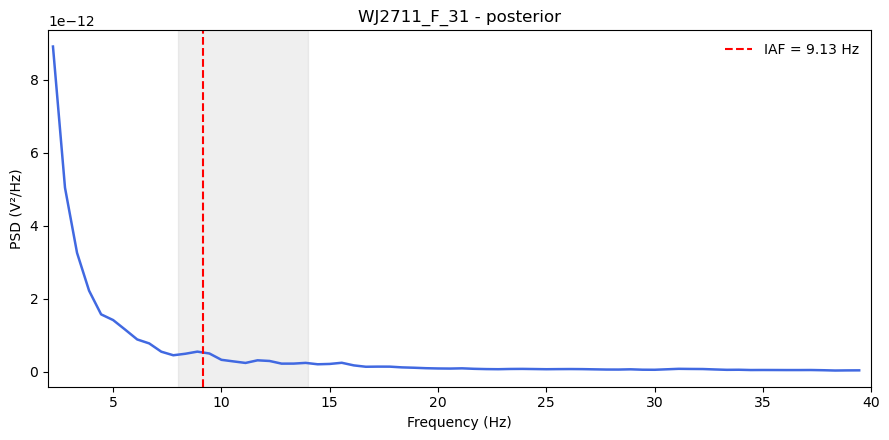


Subject: WK1312_F_29 | Region: posterior
- IAF: 12.68 Hz
- Alpha peak power: 2.077440e-01 V²/Hz
- Method: FOOOF


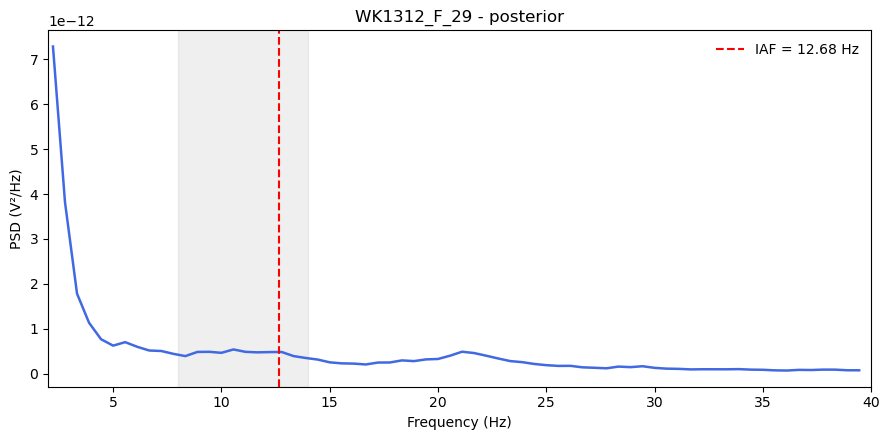


Subject: WK2201_F_21 | Region: posterior
- IAF: 10.58 Hz
- Alpha peak power: 4.517083e-01 V²/Hz
- Method: FOOOF


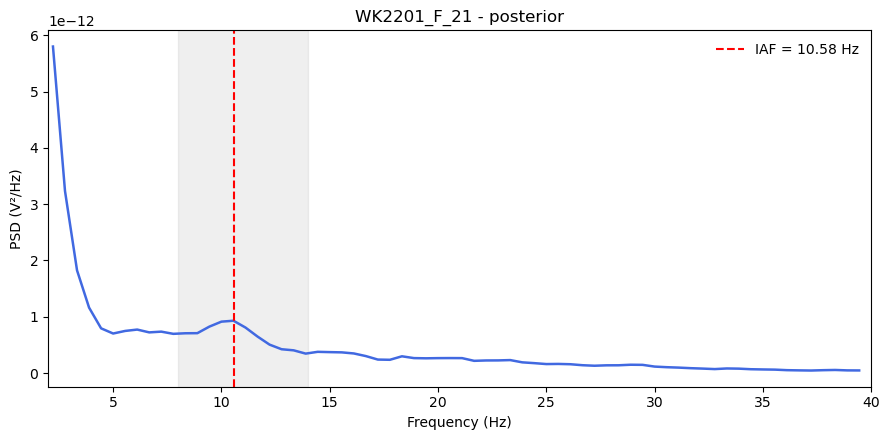


Subject: WU2110_F_21 | Region: posterior
- IAF: 8.31 Hz
- Alpha peak power: 1.076791e-01 V²/Hz
- Method: FOOOF


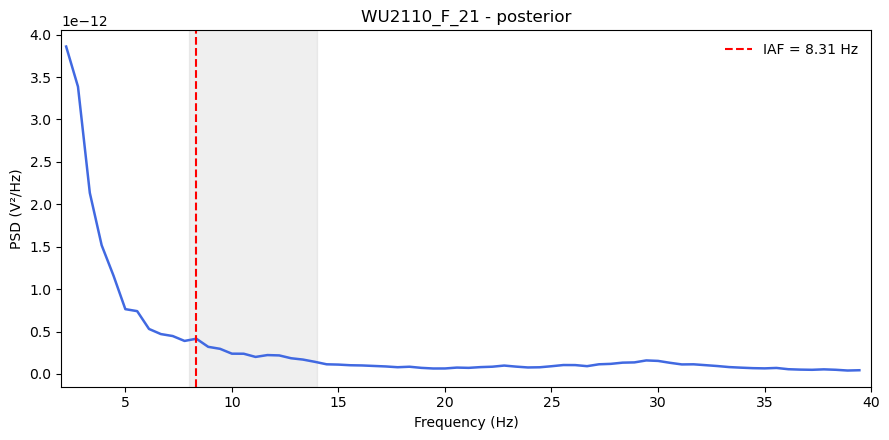


Analysis complete.
Results saved to: C:\Users\aleks\WPR_IAF\IAF_results


In [133]:
#PROCESSING FILES
epoch_files = sorted(
    set(DATA_DIR.rglob("*-epo.fif"))
    | set(DATA_DIR.rglob("*_epo.fif"))
)

if not epoch_files:
    raise FileNotFoundError(
        f"No epochs files found in {DATA_DIR.resolve()}"
    )

results = []

for file_path in epoch_files:
    region_name = file_path.parent.name.lower()

    if region_name not in REGIONS:
        continue

    subject_id = get_subject_id(file_path)

    epochs = mne.read_epochs(
        file_path,
        preload=True,
        verbose=False,
    )

    freqs, psd, used_channels = calculate_roi_psd(
        epochs,
        REGIONS[region_name],
    )

    if freqs is None:
        print(f"Skipping {subject_id} ({region_name}): no usable ROI channels.")
        continue

    iaf, peak_power, method = estimate_iaf(freqs, psd)

    # Printing the results directly in the notebook output
    print(f"\nSubject: {subject_id} | Region: {region_name}")

    if np.isfinite(iaf):
        print(f"- IAF: {iaf:.2f} Hz")
        print(f"- Alpha peak power: {peak_power:.6e} V²/Hz")
    else:
        print("- IAF: Not available")
        print("- Alpha peak power: Not available")

    print(f"- Method: {method}")

    plot_path = PLOTS_DIR / f"{subject_id}_{region_name}_PSD.png"

    plot_roi_psd(
        freqs,
        psd,
        iaf,
        subject_id,
        region_name,
        plot_path,
    )

    results.append({
        "subject_id": subject_id,
        "region": region_name,
        "IAF": iaf,
        "alpha_peak_power": peak_power,
        "IAF_method": method,
        "n_epochs": len(epochs),
        "n_channels": len(used_channels),
    })

#SAVING RESULTS
if not results:
    raise RuntimeError("No results were produced. Check the input files and folders.")

results_df = pd.DataFrame(results)

results_df.to_csv(
    OUTPUT_DIR / "IAF_all_subjects_long.csv",
    index=False,
)

if not results_df.duplicated(["subject_id", "region"]).any():
    wide_df = results_df.pivot(
        index="subject_id",
        columns="region",
        values="IAF",
    ).reset_index()

    wide_df.to_csv(
        OUTPUT_DIR / "IAF_two_regions.csv",
        index=False,
    )

print("\nAnalysis complete.")
print(f"Results saved to: {OUTPUT_DIR.resolve()}")